In [1]:
try:
    import h2o
except:
    !pip install -qq -U h2o
    import h2o

from h2o import H2OFrame
from h2o.automl import H2OAutoML

print("h2o version:", h2o.__version__)

h2o version: 3.46.0.12


In [2]:
try:
    from colorama import Fore, Style
except:
    !pip install -q colorama
    from colorama import Fore, Style

%matplotlib inline
%config InlineBackend.figure_format = 'svg'

In [3]:
## -- System dependencies --
import sys, os, gc
import torch

## -- Device-Agnostic (GPU/CPU) --
def get_system_info():
    if torch.cuda.is_available():
        return f"GPU: {torch.cuda.get_device_name(0)}"
    else:
        return f"CPU: {os.cpu_count()}"

get_system_info()

'CPU: 4'

In [4]:
## -- Data Manipulation --
import numpy as np, pandas as pd, random

## -- Visualization --
from IPython.display import display, Image
import matplotlib.pyplot as plt
import seaborn as sns
# import shap

## -- Functional Tools --
import itertools
from tqdm.auto import tqdm
from time import time, sleep

## -- Machine Learning --
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.utils.class_weight import compute_class_weight
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.model_selection import KFold, StratifiedKFold, train_test_split
from sklearn.metrics import roc_auc_score, log_loss, RocCurveDisplay, ConfusionMatrixDisplay
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, label_binarize, TargetEncoder as skTE

import warnings
warnings.simplefilter('ignore')
warnings.filterwarnings('ignore')

## -- Global Settings --
# sklearn.set_config(transform_output='pandas')

# pd.options.mode.copy_on_write = True
pd.set_option('display.max_columns', 100)
# sns.set_style("whitegrid")
# plt.style.use('ggplot')

warnings

<module 'warnings' from '/usr/lib/python3.13/warnings.py'>

In [5]:
TEAL, GOLD, CORAL, BLUE, DARK, CRIM, MUTED, INK, PAPER = '#168c91','#e8b44f','#dc705a',\
                                                         'dodgerblue','#0B4F7A','crimson',\
                                                         '#627D98','#102A43','#faf9f5'
plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': PAPER,
    'savefig.facecolor': PAPER,
    'font.family': 'DejaVu Sans',
    'font.size': 9,
    'axes.titlesize': 11,
    'axes.titleweight': 'semibold',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': DARK,
    'ytick.color': DARK,
    'axes.edgecolor': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.color': MUTED,
    'patch.edgecolor': DARK,
    # 'patch.force_edgecolor': True,
    # 'patch.linewidth': 1.5,
    # 'figure.dpi':110,
    # 'savefig.dpi':160,
})
# CMAP = LinearSegmentedColormap.from_list('atlas', ['#f0f5ef','#a9d6ca',TEAL,INK])
sns.set_palette([TEAL, GOLD, CORAL, BLUE, MUTED, CRIM, DARK, INK, PAPER])

## -- Set Global Seed --
CFG = {
    'FOLDS':  5,
    'SEED':   42,
    'GREEN':  '\033[32m',
    'YELLOW': '\033[33m',
    'RESET':  '\033[0m'
}

print(f"CLASSIC {CFG['GREEN']} GREEN {CFG['RESET']} {CFG['YELLOW']} YELLOW {CFG['RESET']}")

CLASSIC  GREEN   YELLOW 


In [6]:
## -- ⚠️ IMPORTANT: SELECT PLATFORM ⚠️ --
PLATFORM = "kaggle" # -> 'colab' 'kaggle'

if PLATFORM == "kaggle":
    PATH   = "/kaggle/input/competitions/playground-series-s6e11/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    ORIG_PATH = "/kaggle/input/datasets/uditjain13/credit-card-fraud-detection-2026/"
    orig = pd.read_csv(ORIG_PATH+"credit_card_fraud_2026.csv")
elif PLATFORM == "colab":
    from google.colab import drive
    drive.mount("/content/drive")
    PATH   = "/content/drive/MyDrive/-- shared_notebooks --/Ps6e11 | Credit Card Fraud/_fraud_data/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    orig   = pd.read_csv(PATH+"credit_card_fraud_2026.csv")

TARGET, ID = 'is_fraud', 'id'

## -- Check if id is unique --
if ID in train.columns:
    if train.id.is_unique:
        print(f"Train ID column is unique: {train.id.is_unique}... Dropped ✅!")
        train = train.drop(columns=[ID])
        test  = test.drop(columns=[ID])
        if ID in orig.columns:
            orig = orig.drop(columns=[ID])

Train ID column is unique: True... Dropped ✅!


In [7]:
# train[TARGET] = train[TARGET].map({True: 1, False: 0})
# orig[TARGET] = orig[TARGET].map({True: 1, False: 0})

obj = train.select_dtypes(include=["object", "category"]).columns.tolist()
bol = train.select_dtypes(include=[bool]).columns.tolist()

cat_cols  = [c for c in obj if c not in [TARGET]]
bool_cols = [c for c in bol if c not in [TARGET]]
num_cols  = [c for c in train.columns if c not in cat_cols+bool_cols+[TARGET]]
base_cols = [c for c in train.columns if c not in [TARGET]]

train = train[base_cols+[TARGET]]
orig  = orig[base_cols+[TARGET]]
test  = test[base_cols]

for (name, df) in {"Train": train, "Test": test, 'Orig': orig}.items(): #
    print(f"{name:5s} shape: {df.shape}")
    
print(f"\nDataFrame type: {type(train)}")
print(f"Total Numerical: {len(num_cols)}")
print(f"Total Categorical: {len(cat_cols)}")
print(f"Total Boolean: {len(bool_cols)}")
print(f"Total base features: {len(base_cols)}")

Train shape: (699960, 25)
Test  shape: (299984, 24)
Orig  shape: (20000, 25)

DataFrame type: <class 'pandas.core.frame.DataFrame'>
Total Numerical: 13
Total Categorical: 5
Total Boolean: 6
Total base features: 24


In [8]:
float_cols = [
    'amount_usd', 'account_balance_usd',
    'hours_since_last_txn', 'distance_from_home_km',
    'velocity_score', 'merchant_risk_score',
]

int_cols = [
    'customer_age', 'card_age_months', 'time_of_day_hour', 'txn_count_last_24h',
    # 'cvv_retry_count', 'day_of_week', 'prior_disputes',
]

train.head()

,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


In [9]:
train_len = len(train)
test_len  = len(test)

n_unique = train.nunique().sort_values()
n_unique

used_vpn                            2
is_fraud                            2
is_ai_generated_scam_attempt        2
billing_shipping_mismatch           2
is_foreign_transaction              2
ip_country_mismatch                 2
is_new_merchant                     2
cvv_retry_count                     4
channel                             5
prior_disputes                      5
auth_method                         5
card_type                           5
day_of_week                         7
device_type                         8
merchant_category                  12
txn_count_last_24h                 12
time_of_day_hour                   24
card_age_months                    49
customer_age                       64
velocity_score                    666
merchant_risk_score               950
hours_since_last_txn             3633
distance_from_home_km            4365
amount_usd                      13387
account_balance_usd             43317
dtype: int64

In [10]:
def get_class_weights(y):
    """
    y: Current y labels -> numpy array or series
    """
    cls_ = np.unique(y)
    wts_ = compute_class_weight("balanced", classes=cls_, y=y)
    return dict(zip(cls_, wts_))

def get_sample_weights(y, y_true, opt='auto'):
    """
    y: Current y labels -> numpy array or series
    y_true: True labels -> numpy array or series
    opt: 'auto' generate weight or pass a custom dict -> label: weight
    """
    if opt != 'auto':
        return np.array([opt[label] for label in y])
    else:
        cls_ = np.unique(y_true)
        wts_ = compute_class_weight('balanced', classes=cls_, y=y_true)
        cls_wts = dict(zip(cls_, wts_))
        return np.array([cls_wts[label] for label in y])

def reduce_memory(df):
    old_size = sys.getsizeof(df) / (1024**2)
    for c in tqdm(df.columns, desc='Reducing memory...'):
        if df[c].dtype == np.int64:
            ## -- Downcast Integer type ---
            if df[c].min() > np.iinfo(np.int32).min and df[c].max() < np.iinfo(np.int32).max:
                df[c] = df[c].astype(np.int32)
                # if df[c].min() > np.iinfo(np.int16).min and df[c].max() < np.iinfo(np.int16).max:
                #     df[c] = df[c].astype(np.int16)
                #     if df[c].min() > np.iinfo(np.int8).min and df[c].max() < np.iinfo(np.int8).max:
                #         df[c] = df[c].astype(np.int8)
        elif df[c].dtype == np.float64:
            ## -- Downcast Float type -----
            if df[c].min() > np.finfo(np.float32).min and df[c].max() < np.finfo(np.float32).max:
                df[c] = df[c].astype(np.float32)
                # if df[c].min() > np.finfo(np.float16).min and df[c].max() < np.finfo(np.float16).max:
                #     df[c] = df[c].astype(np.float16)

    new_size = sys.getsizeof(df) / (1024**2)
    print(f"Size before process: {old_size:.1f}MB\nSize after process : {new_size:.1f}MB\n")

    return df

print('- Helper functions ready -')

- Helper functions ready -


## FEATURE ENGINEERING

In [11]:
from sklearn.base import BaseEstimator, TransformerMixin ## ===== Target/Category Mean ENCODERS =====

class TargetEncoder(BaseEstimator, TransformerMixin):
    """
    Target Encoder that supports multiple aggregation functions,
    internal cross-validation for leakage prevention, and smoothing.

    Parameters
    ----------
    cols_to_encode : list of str
        List of column names to be target encoded.

    aggs : list of str, default=['mean']
        List of aggregation functions to apply. Any function accepted by
        pandas' `.agg()` method is supported, such as:
        'mean', 'std', 'var', 'min', 'max', 'skew', 'nunique', 
        'count', 'sum', 'median'.
        Smoothing is applied only to the 'mean' aggregation.

    cv : int, default=5
        Number of folds for cross-validation in fit_transform.

    smooth : float or 'auto', default='auto'
        The smoothing parameter `m`. A larger value puts more weight on the 
        global mean. If 'auto', an empirical Bayes estimate is used.
        
    drop_original : bool, default=False
        If True, the original columns to be encoded are dropped.
    """
    def __init__(self, cols_to_encode, aggs=['mean'], cv=5, smooth='auto', drop_original=False):
        self.cols_to_encode = cols_to_encode
        self.aggs = aggs
        self.cv = cv
        self.smooth = smooth
        self.drop_original = drop_original
        self.mappings_ = {}
        self.global_stats_ = {}

    def fit(self, X, y):
        """
        Learn mappings from the entire dataset.
        These mappings are used for the transform method on validation/test data.
        """
        temp_df = X.copy()
        temp_df['target'] = y

        # Learn global statistics for each aggregation
        for agg_func in self.aggs:
            self.global_stats_[agg_func] = y.agg(agg_func)

        # Learn category-specific mappings
        for col in self.cols_to_encode:
            self.mappings_[col] = {}
            for agg_func in self.aggs:
                mapping = temp_df.groupby(col)['target'].agg(agg_func)
                self.mappings_[col][agg_func] = mapping
        
        return self

    def transform(self, X):
        """
        Apply learned mappings to the data.
        Unseen categories are filled with global statistics.
        """
        X_transformed = X.copy()
        for col in self.cols_to_encode:
            for agg_func in self.aggs:
                new_col_name = f"TE_{col}_{agg_func}"
                map_series = self.mappings_[col][agg_func]
                X_transformed[new_col_name] = X[col].map(map_series)
                X_transformed[new_col_name].fillna(self.global_stats_[agg_func], inplace=True)
        
        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)
            
        return X_transformed

    def fit_transform(self, X, y):
        """
        Fit and transform the data using internal cross-validation to prevent leakage.
        """
        # First, fit on the entire dataset to get global mappings for transform method
        self.fit(X, y)

        # Initialize an empty DataFrame to store encoded features
        encoded_features = pd.DataFrame(index=X.index)
        
        kf = KFold(n_splits=self.cv, shuffle=True, random_state=42)

        for train_idx, val_idx in kf.split(X, y):
            X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
            X_val = X.iloc[val_idx]
            
            temp_df_train = X_train.copy()
            temp_df_train['target'] = y_train

            for col in self.cols_to_encode:
                # --- Calculate mappings only on the training part of the fold ---
                for agg_func in self.aggs:
                    new_col_name = f'TE_{col}_{agg_func}'
                    
                    # Calculate global stat for this fold
                    fold_global_stat = y_train.agg(agg_func)
                    
                    # Calculate category stats for this fold
                    mapping = temp_df_train.groupby(col)['target'].agg(agg_func)

                    # --- Apply smoothing only for 'mean' aggregation ---
                    if agg_func == 'mean':
                        counts = temp_df_train.groupby(col)['target'].count()
                        
                        m = self.smooth
                        if self.smooth == 'auto':
                            # Empirical Bayes smoothing
                            variance_between = mapping.var()
                            avg_variance_within = temp_df_train.groupby(col)['target'].var().mean()
                            if variance_between > 0:
                                m = avg_variance_within / variance_between
                            else:
                                m = 0  # No smoothing if no variance between groups
                        
                        # Apply smoothing formula
                        smoothed_mapping = (counts * mapping + m * fold_global_stat) / (counts + m)
                        encoded_values = X_val[col].map(smoothed_mapping)
                    else:
                        encoded_values = X_val[col].map(mapping)
                    
                    # Store encoded values for the validation fold
                    encoded_features.loc[X_val.index, new_col_name] = encoded_values.fillna(fold_global_stat)

        # Merge with original DataFrame
        X_transformed = X.copy()
        for col in encoded_features.columns:
            X_transformed[col] = encoded_features[col]
            
        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)
            
        return X_transformed


class CategoryMeanTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols=None):
        self.cat_cols = cat_cols
        self.mappings_ = {}
    def fit(self, X, y):
        X = X.copy()
        if self.cat_cols is None:
            self.cat_cols = X.select_dtypes(include=['category']).columns.tolist()
        self.mappings_ = {}
        for col in self.cat_cols:
            df_temp = pd.DataFrame({col: X[col], 'y': y})
            group_means = df_temp.groupby(col, dropna=False)['y'].mean()
            sorted_categories = group_means.sort_values().index
            self.mappings_[col] = {cat: i for i, cat in enumerate(sorted_categories)}
        return self

    def transform(self, X, y=None):
        X = X.copy()
        for col, mapping in self.mappings_.items():
            if col in X.columns:
                X[col] = X[col].map(mapping)
        return X

In [12]:
def original_TE(
    orig: pd.DataFrame,
    df: pd.DataFrame,
    features: list=None,
    target: str=None,
    aggs: list=None,
    fill_nan: bool=False,
):

    if features is None or len(features) == 0:
        return df.copy()

    if aggs is None or len(aggs) == 0:
        return df.copy()

    X_df = df.copy()

    orig_cols = []
    maps = {}

    valid_features = [col for col in features if col in orig.columns]

    for col in tqdm(valid_features, desc="original_augmenting"):
        for agg_ in aggs:
            agg_key = agg_.lower()
            new_col = f"oTE_{col}_{agg_key}"

            map_key = (col, agg_key)
            if map_key not in maps:
                try:
                    if agg_key == 'mean':
                        map_df = (orig.groupby(col)[target].mean().reset_index(name=new_col))
                    elif agg_key == 'median':
                        map_df = (orig.groupby(col)[target].median().reset_index(name=new_col))
                    elif agg_key == 'count':
                        map_df = (orig.groupby(col).size().reset_index(name=new_col)) #.astype('int32')
                    elif agg_key == 'nunique':
                        map_df = (orig.groupby(col)[target].nunique().reset_index(name=new_col)) #.astype('int32')
                    elif agg_key == 'std':
                        map_df = (orig.groupby(col)[target].std().reset_index(name=new_col))
                    elif agg_key == 'skew':
                        map_df = (orig.groupby(col)[target].skew().reset_index(name=new_col))
                    elif agg_key == 'max':
                        map_df = (orig.groupby(col)[target].max().reset_index(name=new_col))
                    elif agg_key == 'min':
                        map_df = (orig.groupby(col)[target].min().reset_index(name=new_col))
                    else:
                        continue
                except Exception as e:
                    print(f"Warning: failed to create map for col={col}, agg={agg_}: {e}")
                    continue

                maps[map_key] = map_df

            map_df = maps.get(map_key)
            if map_df is None:
                continue

            # Merge maps into each split
            X_df = X_df.merge(map_df.astype('float32'), on=col, how='left')

            orig_cols.append(new_col)

    global_mean   = orig[target].mean()
    global_median = orig[target].median()

    def fill_conditionally(df):
        for c in orig_cols:
            if '_mean' in c or '_max' in c or '_min' in c:
                df[c] = df[c].fillna(global_mean)
            elif '_median' in c:
                df[c] = df[c].fillna(global_median)
            else:
                df[c] = df[c].fillna(0)
        return df

    if fill_nan:
        X_df = fill_conditionally(X_df)

    return X_df, orig_cols

print("-- Data augment function ready! --")

-- Data augment function ready! --


In [13]:
FEATURES = [c for c in train.columns if c not in [ID, TARGET]]

combined = pd.concat([train, test, orig], ignore_index=True)
digit_cols = []

for col in num_cols:
    scaled = np.rint(combined[col].fillna(0) * 10**4).astype("int64")
    for k in range(-2, 3):
        dig_col = f"{col}_DIGIT_{k}"
        combined[dig_col] = (scaled // 10**(k+4) % 10).astype('int8').astype('category')
        digit_cols.append(dig_col)

train = combined.iloc[:train_len]
test = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
orig = combined.iloc[-len(orig):]

# Check nunique, and find which ones are < 2
unique_counts = train[digit_cols].nunique()
drop_cols = unique_counts[unique_counts < 2].index.tolist()

# update digit cols for keep
digit_cols = [i for i in set(digit_cols) if i not in set(drop_cols)]

# drop constant features
train = train.drop(columns=drop_cols)
test  = test.drop(columns=drop_cols)
orig  = orig.drop(columns=drop_cols)

del combined
print(f"Total digit features: {len(digit_cols)}\n")

train[digit_cols].nunique()

Total digit features: 37



distance_from_home_km_DIGIT_-2    10
amount_usd_DIGIT_1                10
account_balance_usd_DIGIT_-1      10
account_balance_usd_DIGIT_1       10
amount_usd_DIGIT_0                10
amount_usd_DIGIT_2                10
velocity_score_DIGIT_-1           10
customer_age_DIGIT_0              10
account_balance_usd_DIGIT_-2      10
card_age_months_DIGIT_1            6
time_of_day_hour_DIGIT_1           3
txn_count_last_24h_DIGIT_0        10
txn_count_last_24h_DIGIT_1         2
account_balance_usd_DIGIT_0       10
merchant_risk_score_DIGIT_-1      10
merchant_risk_score_DIGIT_2        2
prior_disputes_DIGIT_0             5
time_of_day_hour_DIGIT_0          10
velocity_score_DIGIT_0            10
cvv_retry_count_DIGIT_0            4
velocity_score_DIGIT_1             8
amount_usd_DIGIT_-2               10
amount_usd_DIGIT_-1               10
merchant_risk_score_DIGIT_0       10
distance_from_home_km_DIGIT_1      6
card_age_months_DIGIT_0           10
hours_since_last_txn_DIGIT_-1     10
c

In [14]:
def digit_keys(df1, cols=float_cols):
    df = df1.copy()
    """How each number is written: six label-free keys per float column."""
    keys = {}
    for c in cols:
        units = np.rint(df[c].to_numpy() * 100).astype(np.int64)        # 1371.37 -> 137137
        integer = units // 100
        s = pd.Series(integer).astype(str)
        keys[f"{c}__int"] = integer                                      # 1371
        keys[f"{c}__int10"] = units // 1000                              # 137
        keys[f"{c}__tenths"] = units // 10                               # 13713
        keys[f"{c}__cents"] = units % 100                                # 37
        keys[f"{c}__lead1"] = (s.str.len() * 10 + s.str[0].astype(int)).to_numpy()     # 4|1
        keys[f"{c}__lead2"] = (s.str.len() * 100 + s.str[:2].astype(int)).to_numpy()   # 4|13

    new_df = pd.DataFrame(keys, index=df.index)
    full_df = pd.concat([df, new_df], axis=1)
    return full_df, [*keys.keys()]

train, digit_cols2 = digit_keys(train)
test, _ = digit_keys(test)

print(train.shape, test.shape)
train[digit_cols2].nunique()

(699960, 98) (299984, 97)


amount_usd__int                   1144
amount_usd__int10                  235
amount_usd__tenths                4599
amount_usd__cents                  100
amount_usd__lead1                   33
amount_usd__lead2                  217
account_balance_usd__int          4928
account_balance_usd__int10        1116
account_balance_usd__tenths      19083
account_balance_usd__cents         100
account_balance_usd__lead1          28
account_balance_usd__lead2         196
hours_since_last_txn__int           51
hours_since_last_txn__int10          6
hours_since_last_txn__tenths       502
hours_since_last_txn__cents        100
hours_since_last_txn__lead1         15
hours_since_last_txn__lead2         51
distance_from_home_km__int          56
distance_from_home_km__int10         6
distance_from_home_km__tenths      542
distance_from_home_km__cents       100
distance_from_home_km__lead1        15
distance_from_home_km__lead2        56
velocity_score__int                 73
velocity_score__int10    

In [15]:
## -- NUMERIC TO CATEGORY for TargetEncoding -- ⚠️

FEATURES = [c for c in train.columns if c not in [ID, TARGET]]
print("Total features before operation:", len(FEATURES))

combined = pd.concat([train, test, orig], ignore_index=True)
## ------------------------------------------------------------

# -- Duplicate Nums as Cats --
nums_to_cats = []
select_nc = num_cols

for c in tqdm(select_nc, desc="nums_to_cats"):
    n_cat = f"{c}_CAT_"
    combined[n_cat], _ = pd.factorize(combined[c], sort=True)
    combined[n_cat] = combined[n_cat].astype('category')
    nums_to_cats.append(n_cat)

FEATURES = list(set(FEATURES + nums_to_cats))
## ------------------------------------------------------------

train = combined.iloc[:train_len] #[FEATURES+[TARGET]]
test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
orig  = combined.iloc[train_len+test_len:]

del combined
print("Total features after operation:", len(FEATURES))

Total features before operation: 97


nums_to_cats:   0%|          | 0/13 [00:00<?, ?it/s]

Total features after operation: 110


In [16]:
# ## -- Create GROUPERS -- ⚠️

# FEATURES = [c for c in train.columns if c not in [ID, TARGET]]
# print("Total features before operation:", len(FEATURES))

# combined = pd.concat([train, test, orig], ignore_index=True)

# IDX = 'velocity_score'
# GROUPERS = []
# for col in tqdm(float_cols):
#     if col == IDX:
#         continue
#     g_col = f"{col}_VS_GROUPBY".replace(' ', '') + '_mean'
#     combined[g_col] = combined.groupby(['velocity_score'])[col].transform('mean')
#     GROUPERS.append(g_col)

# FEATURES = list(set(FEATURES + GROUPERS))
# ## ------------------------------------------------------------------------
# train = combined.iloc[:train_len]
# test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
# orig  = combined.iloc[train_len+test_len:]

# del combined
# print("Total features after operation:", len(FEATURES))
# train[GROUPERS].head()
# train[GROUPERS].nunique()


In [17]:
# train.head()

In [18]:
# train[GROUPERS].nunique()


In [19]:
# ## -- INTERACTIONS -- ⚠️

# INTER = []

# combined = pd.concat([train, test, orig], ignore_index=True)
# # ------------------------------------------------------------------------
# # combo_2_1 = list(itertools.combinations(cat_cols, 2))
# # for c1, c2 in tqdm(combo_2_1, desc='Pairwise Sync Encoding'):
# #     n_col = f"Bi_{c1}_X_{c2}"
# #     combo_string = combined[c1].astype(str) + '_' + combined[c2].astype(str)
# #     combined[n_col.strip()] = pd.factorize(combo_string, sort=True)[0].astype('int32')
# #     # combined[n_col] = combined[n_col].astype('category')
# #     INTER.append(n_col)  

# combo_3_1 = list(itertools.combinations(cat_cols, 3)) # +[age_n]
# for c1, c2, c3 in tqdm(combo_3_1, desc='Triplewise Sync Encoding'):
#     n_col = f"Tri_{c1}_X_{c2}_X_{c3}"
#     combo_string = combined[c1].astype(str) + '_' + combined[c2].astype(str) + '_' + combined[c3].astype(str)
#     combined[n_col] = pd.factorize(combo_string, sort=True)[0].astype('int32')
#     # combined[n_col] = combined[n_col].astype('category')
#     INTER.append(n_col)

# # combo_1_to_many = list(itertools.product(cat_cols, ["Age"]))
# # for c1, c2 in tqdm(combo_1_to_many, desc='One-2-Many Sync Encoding'):
# #     n_col = f"Bi2_{c1}_X_{c2}"
# #     combo_string = combined[c1].astype(str) + '_' + combined[c2].astype(str)
# #     combined[n_col.strip()] = pd.factorize(combo_string, sort=True)[0].astype('int32')
# #     # combined[n_col] = combined[n_col].astype('category')
# #     INTER.append(n_col)
# # ------------------------------------------------------------------------
# for n_col in INTER:
#     train[n_col] = combined[n_col].iloc[:train_len].values
#     test[n_col]  = combined[n_col].iloc[train_len:train_len + test_len].values
#     orig[n_col]  = combined[n_col].iloc[train_len + test_len:].values

# print(f"Total Interaction Features: {INTER}")

# del combined
# # train[INTER].head()

In [20]:
USE_FULL_TRAIN = True

x_sample, x_sample2 = train_test_split(
    train,
    train_size=90_000,
    stratify=train[TARGET],
    random_state=42
)

train_X = train.copy() if USE_FULL_TRAIN else x_sample.reset_index(drop=True)
print(train_X.shape, type(train_X))

FEATURES = [c for c in train_X.columns if c not in [ID, TARGET]]
print("Total Features:", len(FEATURES))

print(f"Train shape {train_X.shape}")
train_X.head()

(699960, 111) <class 'pandas.core.frame.DataFrame'>
Total Features: 110
Train shape (699960, 111)


,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud,amount_usd_DIGIT_-2,amount_usd_DIGIT_-1,amount_usd_DIGIT_0,amount_usd_DIGIT_1,amount_usd_DIGIT_2,hours_since_last_txn_DIGIT_-2,hours_since_last_txn_DIGIT_-1,hours_since_last_txn_DIGIT_0,hours_since_last_txn_DIGIT_1,txn_count_last_24h_DIGIT_0,txn_count_last_24h_DIGIT_1,distance_from_home_km_DIGIT_-2,distance_from_home_km_DIGIT_-1,distance_from_home_km_DIGIT_0,distance_from_home_km_DIGIT_1,card_age_months_DIGIT_0,card_age_months_DIGIT_1,customer_age_DIGIT_0,customer_age_DIGIT_1,account_balance_usd_DIGIT_-2,account_balance_usd_DIGIT_-1,account_balance_usd_DIGIT_0,account_balance_usd_DIGIT_1,account_balance_usd_DIGIT_2,cvv_retry_count_DIGIT_0,...,prior_disputes_DIGIT_0,amount_usd__int,amount_usd__int10,amount_usd__tenths,amount_usd__cents,amount_usd__lead1,amount_usd__lead2,account_balance_usd__int,account_balance_usd__int10,account_balance_usd__tenths,account_balance_usd__cents,account_balance_usd__lead1,account_balance_usd__lead2,hours_since_last_txn__int,hours_since_last_txn__int10,hours_since_last_txn__tenths,hours_since_last_txn__cents,hours_since_last_txn__lead1,hours_since_last_txn__lead2,distance_from_home_km__int,distance_from_home_km__int10,distance_from_home_km__tenths,distance_from_home_km__cents,distance_from_home_km__lead1,distance_from_home_km__lead2,velocity_score__int,velocity_score__int10,velocity_score__tenths,velocity_score__cents,velocity_score__lead1,velocity_score__lead2,merchant_risk_score__int,merchant_risk_score__int10,merchant_risk_score__tenths,merchant_risk_score__cents,merchant_risk_score__lead1,merchant_risk_score__lead2,amount_usd_CAT_,hours_since_last_txn_CAT_,txn_count_last_24h_CAT_,distance_from_home_km_CAT_,card_age_months_CAT_,customer_age_CAT_,account_balance_usd_CAT_,cvv_retry_count_CAT_,velocity_score_CAT_,time_of_day_hour_CAT_,day_of_week_CAT_,merchant_risk_score_CAT_,prior_disputes_CAT_
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,0.0,6,1,1,6,0,7,7,9,0,1,0,8,7,7,1,8,4,6,5,5,3,9,6,2,0,...,0,61.0,6.0,611.0,16.0,26.0,261.0,1269.0,126.0,12693.0,35.0,41.0,412.0,9.0,0.0,97.0,77.0,19.0,109.0,17.0,1.0,177.0,78.0,21.0,217.0,5.0,0.0,55.0,50.0,15.0,105.0,29.0,2.0,292.0,20.0,22.0,229.0,5318,976,1,1775,25,38,21485,0,55,17,3,293,0
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0,3,8,4,2,0,4,5,1,0,3,0,6,0,3,1,8,3,8,2,0,0,3,3,2,0,...,1,24.0,2.0,248.0,83.0,22.0,224.0,3233.0,323.0,32330.0,0.0,43.0,432.0,1.0,0.0,15.0,54.0,11.0,101.0,13.0,1.0,130.0,6.0,21.0,213.0,33.0,3.0,334.0,40.0,23.0,233.0,29.0,2.0,299.0,90.0,22.0,229.0,2179,153,3,1304,15,10,43629,0,335,23,5,300,1
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,0.0,6,3,6,0,0,0,2,1,0,4,0,7,1,8,0,0,5,5,5,8,8,6,4,0,0,...,0,6.0,0.0,63.0,36.0,16.0,106.0,1046.0,104.0,10468.0,88.0,41.0,410.0,1.0,0.0,12.0,20.0,11.0,101.0,8.0,0.0,81.0,17.0,18.0,108.0,35.0,3.0,358.0,80.0,23.0,235.0,24.0,2.0,241.0,10.0,22.0,224.0,430,119,4,817,27,37,16650,0,359,15,0,242,0
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0,4,4,7,3,0,3,1,5,0,4,0,7,6,8,0,8,4,8,4,7,6,7,1,2,0,...,0,37.0,3.0,374.0,44.0,23.0,237.0,2217.0,221.0,22176.0,67.0,42.0,422.0,5.0,0.0,51.0,13.0,15.0,105.0,8.0,0.0,86.0,67.0,18.0,108.0,20.0,2.0,207.0,70.0,22.0,220.0,41.0,4.0,419.0,90.0,24.0,241.0,3322,512,4,867,25,30,34746,0,207,7,3,420,0
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0

In [21]:
## -- Handle optional original table aggregations --
USE_ORIGINAL = False

import_cols  = [] # 

if USE_ORIGINAL:
    aggs_ = ["mean", "count"]  # "mean", "count", "std", "skew", "nunique", 
    feats = FEATURES.copy()
    x_train, orig_cols = original_TE(
        orig, train_X, target=TARGET, features = import_cols,
        aggs=aggs_, #fill_nan=True
    )
    x_test, _ = original_TE(
        orig, test, target=TARGET, features = import_cols,
        aggs=aggs_, #fill_nan=True
    )
    feats.extend(orig_cols)
    X = x_train[feats]
    X_test = x_test[feats]
    y = train_X[TARGET].astype(np.int8)
else:
    X = train_X[FEATURES]
    X_test = test[FEATURES]
    y = train_X[TARGET].astype(np.int8)

print(X.shape, type(X))
X.head()

(699960, 110) <class 'pandas.core.frame.DataFrame'>


,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,amount_usd_DIGIT_-2,amount_usd_DIGIT_-1,amount_usd_DIGIT_0,amount_usd_DIGIT_1,amount_usd_DIGIT_2,hours_since_last_txn_DIGIT_-2,hours_since_last_txn_DIGIT_-1,hours_since_last_txn_DIGIT_0,hours_since_last_txn_DIGIT_1,txn_count_last_24h_DIGIT_0,txn_count_last_24h_DIGIT_1,distance_from_home_km_DIGIT_-2,distance_from_home_km_DIGIT_-1,distance_from_home_km_DIGIT_0,distance_from_home_km_DIGIT_1,card_age_months_DIGIT_0,card_age_months_DIGIT_1,customer_age_DIGIT_0,customer_age_DIGIT_1,account_balance_usd_DIGIT_-2,account_balance_usd_DIGIT_-1,account_balance_usd_DIGIT_0,account_balance_usd_DIGIT_1,account_balance_usd_DIGIT_2,cvv_retry_count_DIGIT_0,velocity_score_DIGIT_-1,...,prior_disputes_DIGIT_0,amount_usd__int,amount_usd__int10,amount_usd__tenths,amount_usd__cents,amount_usd__lead1,amount_usd__lead2,account_balance_usd__int,account_balance_usd__int10,account_balance_usd__tenths,account_balance_usd__cents,account_balance_usd__lead1,account_balance_usd__lead2,hours_since_last_txn__int,hours_since_last_txn__int10,hours_since_last_txn__tenths,hours_since_last_txn__cents,hours_since_last_txn__lead1,hours_since_last_txn__lead2,distance_from_home_km__int,distance_from_home_km__int10,distance_from_home_km__tenths,distance_from_home_km__cents,distance_from_home_km__lead1,distance_from_home_km__lead2,velocity_score__int,velocity_score__int10,velocity_score__tenths,velocity_score__cents,velocity_score__lead1,velocity_score__lead2,merchant_risk_score__int,merchant_risk_score__int10,merchant_risk_score__tenths,merchant_risk_score__cents,merchant_risk_score__lead1,merchant_risk_score__lead2,amount_usd_CAT_,hours_since_last_txn_CAT_,txn_count_last_24h_CAT_,distance_from_home_km_CAT_,card_age_months_CAT_,customer_age_CAT_,account_balance_usd_CAT_,cvv_retry_count_CAT_,velocity_score_CAT_,time_of_day_hour_CAT_,day_of_week_CAT_,merchant_risk_score_CAT_,prior_disputes_CAT_
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,6,1,1,6,0,7,7,9,0,1,0,8,7,7,1,8,4,6,5,5,3,9,6,2,0,5,...,0,61.0,6.0,611.0,16.0,26.0,261.0,1269.0,126.0,12693.0,35.0,41.0,412.0,9.0,0.0,97.0,77.0,19.0,109.0,17.0,1.0,177.0,78.0,21.0,217.0,5.0,0.0,55.0,50.0,15.0,105.0,29.0,2.0,292.0,20.0,22.0,229.0,5318,976,1,1775,25,38,21485,0,55,17,3,293,0
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,3,8,4,2,0,4,5,1,0,3,0,6,0,3,1,8,3,8,2,0,0,3,3,2,0,4,...,1,24.0,2.0,248.0,83.0,22.0,224.0,3233.0,323.0,32330.0,0.0,43.0,432.0,1.0,0.0,15.0,54.0,11.0,101.0,13.0,1.0,130.0,6.0,21.0,213.0,33.0,3.0,334.0,40.0,23.0,233.0,29.0,2.0,299.0,90.0,22.0,229.0,2179,153,3,1304,15,10,43629,0,335,23,5,300,1
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,6,3,6,0,0,0,2,1,0,4,0,7,1,8,0,0,5,5,5,8,8,6,4,0,0,8,...,0,6.0,0.0,63.0,36.0,16.0,106.0,1046.0,104.0,10468.0,88.0,41.0,410.0,1.0,0.0,12.0,20.0,11.0,101.0,8.0,0.0,81.0,17.0,18.0,108.0,35.0,3.0,358.0,80.0,23.0,235.0,24.0,2.0,241.0,10.0,22.0,224.0,430,119,4,817,27,37,16650,0,359,15,0,242,0
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,4,4,7,3,0,3,1,5,0,4,0,7,6,8,0,8,4,8,4,7,6,7,1,2,0,7,...,0,37.0,3.0,374.0,44.0,23.0,237.0,2217.0,221.0,22176.0,67.0,42.0,422.0,5.0,0.0,51.0,13.0,15.0,105.0,8.0,0.0,86.0,67.0,18.0,108.0,20.0,2.0,207.0,70.0,22.0,220.0,41.0,4.0,419.0,90.0,24.0,241.0,3322,512,4,867,25,30,34746,0,207,7,3,420,0
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4

## Config | Trainer

In [22]:
# ## -- Trainer for h2o.H20Frame
# def Trainer_CV(model_name, params, train_df, test_df, features, target, kf, cat_cols):
#     print(f"\n===== Starting CV: {model_name} =====")
#     start = time()

#     y = train_df[target]
#     num_cls = y.nunique()

#     oof_preds = np.zeros((len(train_df), num_cls))
#     test_preds = np.zeros((len(test_df), num_cls))
#     fold_scores = []

#     oof_glm = np.zeros((len(train_df), num_cls))
#     oof_gbm = np.zeros((len(train_df), num_cls))
#     oof_drf = np.zeros((len(train_df), num_cls))
#     oof_xgb = np.zeros((len(train_df), num_cls))
#     oof_dpl = np.zeros((len(train_df), num_cls))

#     test_glm = np.zeros((len(test_df), num_cls))
#     test_gbm = np.zeros((len(test_df), num_cls))
#     test_drf = np.zeros((len(test_df), num_cls))
#     test_xgb = np.zeros((len(test_df), num_cls))
#     test_dpl = np.zeros((len(test_df), num_cls))

#     h2o_models = [
#         ("glm", oof_glm, test_glm),
#         ("gbm", oof_gbm, test_gbm),
#         ("drf", oof_drf, test_drf),
#         ("xgboost", oof_xgb, test_xgb),
#         ("deeplearning", oof_dpl, test_dpl),
#     ]
#     ## ---------------------------------------------------------------------------------
#     h2o.init(verbose=True, nthreads=os.cpu_count(), max_mem_size="20G")
    
#     test_df[TARGET] = "Null"
#     df_ = pd.concat([train_df, test_df])
#     h2o_df = H2OFrame(df_)

#     ## -- Split train set --
#     h2o_train = h2o_df[h2o_df[TARGET] != "Null"]
#     h2o_train[TARGET] = h2o_train[TARGET].asfactor()

#     ## -- Split test set --
#     h2o_test = h2o_df[h2o_df[TARGET] == "Null"]
#     # h2o_test = h2o_test.drop([TARGET])

#     for col in cat_cols:
#         h2o_train[col] = h2o_train[col].asfactor()
#         h2o_test[col]  = h2o_test[col].asfactor()
#     ## ---------------------------------------------------------------------------------

#     n_splits = kf.n_splits

#     for idx, (train_idx, val_idx) in enumerate(kf.split(train_df[features], y)):
#         print(f"\n{CFG["YELLOW"]}##### FOLD {idx+1}/{n_splits} | ", end="")

#         train_idx = list(train_idx.ravel())
#         val_idx = list(val_idx.ravel())

#         X_train = h2o_train[[int(i) for i in train_idx], :]
#         X_valid = h2o_train[[int(i) for i in val_idx], :]
#         X_test  = h2o_test[:, features]

#         print(f"Train shape: {X_train.shape}{CFG["RESET"]}")

#         ## --------------------------------------------------------------------------------------
#         model = H2OAutoML(**params)
#         model.train(features, target, training_frame=X_train, validation_frame=X_valid)
#         ## --------------------------------------------------------------------------------------
#         ## -- LEADER MODEL -- 
#         oof_preds_ = model.leader.predict(X_valid).as_data_frame(use_multi_thread=True)
#         oof_preds[val_idx] = oof_preds_.iloc[:, -num_cls:].to_numpy()

#         test_preds_ = model.leader.predict(X_test).as_data_frame(use_multi_thread=True)
#         test_preds += test_preds_.iloc[:, -num_cls:].to_numpy()
#         ## --------------------------------------------------------------------------------------
#         ## -- PER MODEL BASELINE -- 
#         for (mod, x_oof, x_tst) in h2o_models:
#             print(f" ••• Predicting with {mod}")
#             algo_model = model.get_best_model(algorithm=mod)

#             if algo_model is not None:
#                 single_oof = algo_model.predict(X_valid).as_data_frame(use_multi_thread=True)
#                 x_oof[val_idx] = single_oof.iloc[:, -num_cls:].to_numpy()

#                 single_test = algo_model.predict(X_test).as_data_frame(use_multi_thread=True)
#                 x_tst += single_test.iloc[:, -num_cls:].to_numpy()
#             else:
#                 print(f"    ⚠️ Warning: No model found for {mod} in this fold.")
#         ## ---------------------------------------------------------------------------------------

#         ## -- Get fold score --
#         # Use target mapping cleanly onto validation series
#         fold_score = balanced_acc(y[val_idx].map(mapping), oof_preds[val_idx])
#         fold_scores.append(fold_score)
#         print(f"{CFG["YELLOW"]} • Fold_{idx+1} bal_acc: {fold_score:.5f}{CFG["RESET"]}")

#     ## -- Average the test predictions outside the main fold loop
#     test_preds /= n_splits

#     ## -- FIX 3: Fixed variable unpacking for clean output messages
#     for (mod, __, x_tst) in tqdm(h2o_models, desc="Averaging model tests"):
#         print(f"• {mod}... ", end="")
#         x_tst /= n_splits

#     ## -- Print CV results
#     print("\n==================================================")
#     print(f"{n_splits}-FOLDS CV: {model_name}")
#     print("==================================================")
#     for i, score in enumerate(fold_scores):
#         print(f" • Fold {i+1} score: {score:.5f}")
    
#     ## -- Final out-of-fold --
#     overall_score = np.round(balanced_acc(y.map(mapping), oof_preds), 5)
#     print("-------------------------------------------------|")
#     print(f"OOF score: {overall_score}")
#     print(f"AVG score: {np.mean(fold_scores):.5f} ± {np.std(fold_scores):.5f}")
#     print("-------------------------------------------------|")
#     print(f'{((time() - start) / 60):.2f} mins')

#     return {
#         "oof_preds": oof_preds,
#         "test_preds": test_preds,
#         "h2o": h2o_models,
#         "score": overall_score,
#         "model": model,
#         "val_data": X_valid, 
#     }

# print("⚙️ Trainer function ready ⚙️")

In [23]:
## -- Trainer for pandas DataFrame
def Trainer_CV(
    model_name, params, X, y, X_test, features, target, kfold,
    cat_cols=None, use_orig=False,
    use_weights=False, use_stack=False,
):
    print(f"\n===== Starting CV: {model_name} | {get_system_info()} =====")
    t0 = time()

    ## - Initialize H2O once -- 
    h2o.init(verbose=False, max_mem_size="20G") 

    # X = train_df[features]
    # y = train_df[target].astype(str)

    N_SPLITS = kfold.n_splits

    oof_preds   = np.zeros(len(X))
    test_preds  = np.zeros(len(X_test))
    fold_scores = []
    
    for idx, (train_idx, val_idx) in enumerate(kfold.split(X, y), 1):
        print()
        print("="*15)
        print(f"### FOLD {idx}/{N_SPLITS}")
        print("="*15)

        X_train, X_valid = X.iloc[train_idx].copy(), X.iloc[val_idx].copy()
        y_train, y_valid = y.iloc[train_idx], y.iloc[val_idx]
        X_tst = X_test.copy()

        # ## -- OPTION: Concatenate original data --
        # X_train = pd.concat([X_train, orig[features]], ignore_index=True)
        # y_train = pd.concat([y_train, orig[target]], ignore_index=True)

        if use_weights:
            print("Using weights ✓")
            def h2o_flat_weights(y):
                class_ratios = y.value_counts(normalize=True).sort_index().values
                print(f"Class_ratios: {class_ratios}")
                proportions = (1 / y.nunique()) / class_ratios
                print(f"Proportions: {proportions}")
                flat_weights = (proportions / min(proportions)).tolist()
                print(f"Flat weights: {flat_weights}")
                return flat_weights

            params['balance_classes'] = True
            params['class_sampling_factors'] = h2o_flat_weights(y_train)

        # Target encoding
        if 'nums_to_cats' in globals():
            te_cols = nums_to_cats + digit_cols2
            # te_cols = nums_to_cats + INTER # + floor_cols + digit_cols + bin_cols
            smooth = 50
            print(f"⚡️ scikit_TE (smooth={smooth}) | features ({len(te_cols)})")
            TE = skTE(target_type='binary', cv=5, smooth=smooth, random_state=42)
            tr_enc = TE.fit_transform(X_train[te_cols], y_train)
            va_enc = TE.transform(X_valid[te_cols])
            ts_enc = TE.transform(X_tst[te_cols])
    
            te_names = [f"TE{smooth}_{col}" for col in te_cols]
            X_train[te_names] = tr_enc
            X_valid[te_names] = va_enc
            X_tst[te_names] = ts_enc

            combos_to_drop = te_cols

            X_train = X_train.drop(columns=combos_to_drop)
            X_valid = X_valid.drop(columns=combos_to_drop)
            X_tst = X_tst.drop(columns=combos_to_drop)

        te_features = [c for c in X_train.columns if c.startswith('TE_')]

        print(f"train = {X_train.shape}, valid = {X_valid.shape}")

        # Prepare frames
        h2o_X_frame = H2OFrame(pd.concat([X_train, y_train], axis=1))
        h2o_V_frame = H2OFrame(pd.concat([X_valid, y_valid], axis=1))
        h2o_valid   = H2OFrame(X_valid)
        h2o_test    = H2OFrame(X_tst)

        # Recognize target as a factor column
        h2o_X_frame[target] = h2o_X_frame[target].asfactor()
        h2o_V_frame[target] = h2o_V_frame[target].asfactor()

        all_cat_cols = cat_cols
        for col in all_cat_cols:
            h2o_X_frame[col] = h2o_X_frame[col].asfactor()
            h2o_V_frame[col] = h2o_V_frame[col].asfactor()
            h2o_valid[col]   = h2o_valid[col].asfactor()
            h2o_test[col]    = h2o_test[col].asfactor()

        print(f"⚙️ H2O_Frame shape: {h2o_X_frame.shape}\n")
        # -------------------------------------------------------------------------------------
        
        model = H2OAutoML(**params)
        model.train(
            y = target,
            training_frame = h2o_X_frame,
            validation_frame = None if use_stack else h2o_V_frame,
        )
        # --------------------------------------------------------------------------------------
        # Leader Model -- 
        oof_predictions = model.leader.predict(h2o_valid).as_data_frame(use_multi_thread=True)
        oof_preds[val_idx] = oof_predictions.iloc[:, -1].to_numpy()

        test_predictions = model.leader.predict(h2o_test)
        display(test_predictions[:5, :])
        test_preds += test_predictions.as_data_frame(use_multi_thread=True).iloc[:, -1].to_numpy()
        # --------------------------------------------------------------------------------------

        fold_score = roc_auc_score(y_valid, oof_preds[val_idx])
        fold_scores.append(fold_score)

        print(f"{CFG['YELLOW']}# FOLD {idx} AUC: {fold_score:.5f}{CFG['RESET']}")
        
    ## -------------------------------------------------------------------------
    # ## -- Fixed variable unpacking for clean output messages
    # for (mod, __, x_tst) in tqdm(h2o_models, desc="Averaging model tests"):
    #     print(f"• {mod}... ", end="")
    #     x_tst /= N_SPLITS

    ## -- Average test predictions
    test_preds /= N_SPLITS
    ## -------------------------------------------------------------------------

    ## -- CV results --
    print("\n==================================================")
    print(f"{N_SPLITS}-FOLD CV: {model_name} | {h2o_X_frame.shape}")
    print("==================================================")
    for i, s in enumerate(fold_scores, 1):
        print(f" • Fold {i} AUC: {s:.5f}")

    ## -- Final out-of-fold score --
    oof_auc = np.round(roc_auc_score(y, oof_preds), 5)
    avg_auc = np.round(np.mean(fold_scores), 5)
    std_auc = np.round(np.std(fold_scores), 5)

    print("-------------------------------------------------|")
    print(f"OOF score: {Fore.YELLOW}{Style.BRIGHT}{oof_auc}{Style.RESET_ALL}")
    print(f"AVG score: {Fore.YELLOW}{Style.BRIGHT}{avg_auc} ± {std_auc}{Style.RESET_ALL}")
    print("-------------------------------------------------|")
    t1 = time()
    tt = (t1-t0)/60
    print(f"{tt:.2f} mins")

    return {
        "oof_preds": oof_preds,
        "test_preds": test_preds,
        "score": avg_auc,
        "model": model,
        "val_data": h2o_V_frame, 
        "name": model_name+f"({h2o_V_frame.shape[1]})",
    }

print("⚙️ Training function ready ⚙️")

⚙️ Training function ready ⚙️


In [24]:
FEATURES = [c for c in X.columns if c not in [ID, TARGET]]
print("Total Features:", len(FEATURES))

FOLDS = 5
skf = StratifiedKFold(n_splits=FOLDS , shuffle=True, random_state=42)

for idx, (t_idx, v_idx) in enumerate(skf.split(X, y)):
    print(f"FOLD {idx+1}/{skf.n_splits} {'-'*25}")
    print(f"  train: {[int(i) for i in t_idx][25:30]}")
    print(f"  valid: {[int(i) for i in v_idx][25:30]}")

Total Features: 110
FOLD 1/5 -------------------------
  train: [36, 37, 38, 39, 40]
  valid: [104, 107, 108, 110, 116]
FOLD 2/5 -------------------------
  train: [26, 27, 28, 29, 30]
  valid: [229, 231, 241, 244, 255]
FOLD 3/5 -------------------------
  train: [30, 32, 33, 34, 35]
  valid: [105, 115, 126, 129, 132]
FOLD 4/5 -------------------------
  train: [36, 37, 38, 39, 41]
  valid: [103, 112, 113, 119, 122]
FOLD 5/5 -------------------------
  train: [32, 33, 34, 35, 36]
  valid: [135, 143, 144, 152, 155]


In [25]:
# !rm -r /kaggle/working/ 

In [26]:
all_predictions = {}

KAGGLE_TIME = 42000
params = {
    'max_models': 60,
    'max_runtime_secs': KAGGLE_TIME//FOLDS, # (60*15)
    # 'max_runtime_secs_per_model': 300,
    # 'nfolds': 4, # 0 if validation_frame is provided, def=-1
    'stopping_rounds': 5,
    'stopping_metric': "AUC",
    # "preprocessing": ['target_encoding'],
    'seed': 42,
}

N_FEATS = len(FEATURES)
for VALUE in [True]:
    n = f"h2o_STACK({N_FEATS})" if VALUE else f"h2o_BEST({N_FEATS})"
    params["nfolds"] = 3 if VALUE else 0
    all_predictions[n] = Trainer_CV(
        model_name=n,
        params=params,
        X=X,
        y=y,
        X_test=X_test,
        features=FEATURES,
        target=TARGET,
        kfold=skf,
        cat_cols = cat_cols + bool_cols + digit_cols,
        use_stack=VALUE, 
        # use_orig=True,
        # use_weights=True,
    )


===== Starting CV: h2o_STACK(110) | CPU: 4 =====

### FOLD 1/5
⚡️ scikit_TE (smooth=50) | features (49)
train = (559968, 110), valid = (139992, 110)
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
⚙️ H2O_Frame shape: (559968, 111)

AutoML progress: |███████████████████████████████████████████████████████████████| (done) 100%
glm prediction progress: |███████████████████████████████████████████████████████| (done) 100%
Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
glm prediction progress: |███████████████████████████████████████████████████████| (done) 100%


predict,p0,p1
0,0.999821,0.000178708
0,0.999899,0.000100873
0,0.918969,0.0810305
0,0.998538,0.00146151
0,0.999459,0.000540876


Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
# FOLD 1 AUC: 0.94811

### FOLD 2/5
⚡️ scikit_TE (smooth=50) | features (49)
train = (559968, 110), valid = (139992, 110)
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
⚙️ H2O_Frame shape: (559968, 111)

AutoML progress: |
00:16:18.961: _train param, Dropping bad and constant columns: [merchant_risk_score_DIGIT_-2]

█████████████████
00:50:33.994: _train param, Dropping bad and constant columns: [merchant_risk_score_DIGIT_-2]

█████
01:02:21.2: _train param, Dropping bad and constant columns: [merchant_risk_score_DIGIT_-2]

███████
01:18:58.533: _train param, Droppi

predict,p0,p1
0,0.999895,0.000104598
0,0.999899,0.00010136
0,0.93225,0.0677503
0,0.99908,0.000919872
0,0.999434,0.000566171


Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
# FOLD 2 AUC: 0.94887

### FOLD 3/5
⚡️ scikit_TE (smooth=50) | features (49)
train = (559968, 110), valid = (139992, 110)
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
⚙️ H2O_Frame shape: (559968, 111)

AutoML progress: |███████████████████████████████████████████████████████████████| (done) 100%
glm prediction progress: |███████████████████████████████████████████████████████| (done) 100%
Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
glm prediction progress: |███████████████████████████████████████████████████████| 

predict,p0,p1
0,0.999839,0.000160835
0,0.999916,8.43462e-05
0,0.924713,0.0752866
0,0.998994,0.00100623
0,0.999433,0.000566689


Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
# FOLD 3 AUC: 0.95407

### FOLD 4/5
⚡️ scikit_TE (smooth=50) | features (49)
train = (559968, 110), valid = (139992, 110)
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
⚙️ H2O_Frame shape: (559968, 111)

AutoML progress: |███████████████████████████████████████████████████████████████| (done) 100%
glm prediction progress: |███████████████████████████████████████████████████████| (done) 100%
Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
glm prediction progress: |███████████████████████████████████████████████████████| 

predict,p0,p1
0,0.999849,0.000151268
0,0.999893,0.000107149
0,0.930734,0.0692657
0,0.998734,0.00126608
0,0.999296,0.000704466


Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
# FOLD 4 AUC: 0.94847

### FOLD 5/5
⚡️ scikit_TE (smooth=50) | features (49)
train = (559968, 110), valid = (139992, 110)
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
⚙️ H2O_Frame shape: (559968, 111)

AutoML progress: |███████████████████████████████████████████████████████████████| (done) 100%
glm prediction progress: |███████████████████████████████████████████████████████| (done) 100%
Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
glm prediction progress: |███████████████████████████████████████████████████████| 

predict,p0,p1
0,0.999866,0.000134045
0,0.999886,0.000113572
0,0.922175,0.0778248
0,0.998993,0.0010072
0,0.999265,0.000734762


Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
# FOLD 5 AUC: 0.94374

5-FOLD CV: h2o_STACK(110) | (559968, 111)
 • Fold 1 AUC: 0.94811
 • Fold 2 AUC: 0.94887
 • Fold 3 AUC: 0.95407
 • Fold 4 AUC: 0.94847
 • Fold 5 AUC: 0.94374
-------------------------------------------------|
OOF score: 0.94862
AVG score: 0.94865 ± 0.00328
-------------------------------------------------|
717.60 mins


In [27]:
# ==================================================
# 3-FOLD CV: h2o_STACK(110)_ | (466640, 111)
# ==================================================
#  • Fold 1 AUC: 0.94752
#  • Fold 2 AUC: 0.95046
#  • Fold 3 AUC: 0.94464
# -------------------------------------------------|
# OOF score: 0.94756
# AVG score: 0.94754 ± 0.00238
# -------------------------------------------------|
# 23.51 mins

# ==================================================
# 3-FOLD CV: h2o_BEST_(110)_ | (466640, 111)
# ==================================================
#  • Fold 1 AUC: 0.94752
#  • Fold 2 AUC: 0.95064
#  • Fold 3 AUC: 0.94507
# -------------------------------------------------|
# OOF score: 0.94775
# AVG score: 0.94774 ± 0.00228
# -------------------------------------------------|
# 24.20 mins

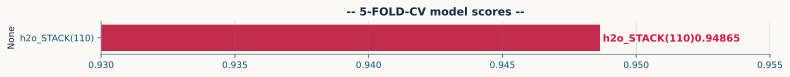

In [28]:
all_names  = {k: v.get("name") for k, v in all_predictions.items() if "name" in v}
all_scores = {k: v.get("score") for k, v in all_predictions.items() if "score" in v}
results_df = pd.Series(all_scores).sort_values(ascending=False) #[:10]

## -- Results --
max_val = results_df.max()
palette = [CRIM if c == max_val else MUTED for c in results_df.values]

plt.figure(figsize=(12, len(results_df)*0.6))

ax1 = sns.barplot(
    x=results_df.values,
    y=results_df.index,
    palette=palette,
    hue=results_df.index,
    orient="h",
    legend=False,
)

for i, s1 in enumerate(results_df.values):
    ax1.text(
        s1+1e-4,
        float(i),
        f"{results_df.index[i]}{s1:.5f}" if s1 == max_val else f"{results_df.index[i]}{s1:.5f}",
        ha="left",
        va='center_baseline',
        size=10,
        weight="semibold",
        color=CRIM if s1 == max_val else MUTED,
    )

plt.xlim((0.93, 0.955))
plt.title(f"-- {FOLDS}-FOLD-CV model scores --")

plt.tight_layout()
plt.show()

h2o_STACK(110)_94865 saved!


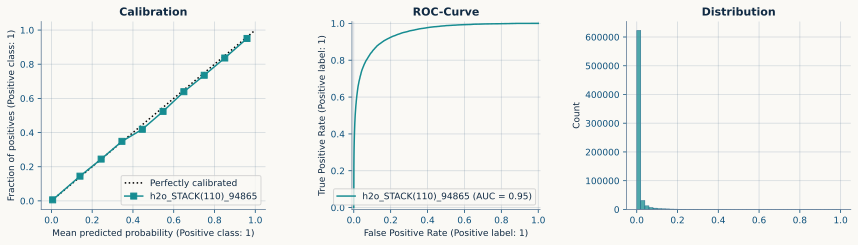

In [29]:
## -- Get oof predictions --
oof_predictions = []

for i, (k, v) in enumerate(all_predictions.items()):
    for key_, data_ in v.items():
        if key_ == "oof_preds":
            n = f"{k}_{str(all_scores[k]).split('.')[1]}"
            np.save(f"oof_{n}.npy", data_)
            print(f"{n} saved!")

            ## -- Plot distributions --
            _, axs = plt.subplots(1, 3, figsize=(12, 3.5)) 
            CalibrationDisplay.from_predictions(train_X[TARGET], data_, n_bins=10, name=n, ax=axs[0])
            axs[0].set_title("Calibration")

            RocCurveDisplay.from_predictions(train_X[TARGET], data_, name=n, ax=axs[1])
            axs[1].set_title("ROC-Curve")

            sns.histplot(data_, ax=axs[2], bins=50)
            axs[2].set_title("Distribution")
            
            plt.tight_layout()
            plt.show()

            print()

In [30]:
## -- Save test predictions/submissions --
model_results = {}

for i, (k, v) in enumerate(all_predictions.items()):
    for j, (x, y) in enumerate(v.items()):
        if x == "test_preds":
            ## -- Base submission file --
            n = f"{k}_{str(all_scores[k]).split('.')[1]}"
            np.save(f"test_{n}.npy", y)

            submit[TARGET] = y
            submit.to_csv(f"submit_{n}.csv", index=False)
            print(f"{n:>17} saved! {y.shape}")

            model_results[n] = y

print()
model_results = pd.DataFrame(model_results)
model_results.head()

h2o_STACK(110)_94865 saved! (299984,)



,h2o_STACK(110)_94865
0,0.000146
1,0.000101
2,0.074232
3,0.001132
4,0.000623


# XAI

In [31]:
## -- Inspect model -- 
model_list = list(all_predictions.keys())
model_list

['h2o_STACK(110)']

In [32]:
get_model = all_predictions[model_list[-1]]
get_model["model"].leader

Model Details
=============
H2OGeneralizedLinearEstimator : Generalized Linear Modeling
Model Key: GLM_1_AutoML_5_20261113_72648


GLM Model: summary
    family    link    regularization               lambda_search                                                                   number_of_predictors_total    number_of_active_predictors    number_of_iterations    training_frame
--  --------  ------  ---------------------------  ------------------------------------------------------------------------------  ----------------------------  -----------------------------  ----------------------  ------------------------------------------------
    binomial  logit   Ridge ( lambda = 2.989E-6 )  nlambda = 30, lambda.max = 2.989, lambda.min = 2.989E-6, lambda.1se = 8.391E-5  418                           418                            59                      AutoML_5_20261113_72648_training_py_645_sid_a948

ModelMetricsBinomialGLM: glm
** Reported on train data. **

MSE: 0.010632417586549186
RMSE: 0.10311361494268924
LogLoss: 0.04381045853963677
AUC: 0.9515909970709603
AUCPR: 0.5382548754925494
Gini: 0.9031819941419206
Null degrees of freedom: 559967
Residual degrees of freedom: 559549
Null deviance: 95080.96606415452
Residual deviance: 49064.90969504665
AIC: 49902.90969504665

Confusion Matrix (Act/Pred) for max f1 @ threshold = 0.27952346321157295
       0       1     Error    Rate
-----  ------  ----  -------  -----------------
0      547552  3065  0.0056   (3065.0/550617.0)
1      4968    4383  0.5313   (4968.0/9351.0)
Total  552520  7448  0.0143   (8033.0/559968.0)

Maximum Metrics: Maximum metrics at their respective thresholds
metric                       threshold    value     idx
---------------------------  -----------  --------  -----
max f1                       0.279523     0.521817  183
max f2                       0.104118     0.551655  260
max f0point5                 0.548287     0.609465  104
max accuracy                 0.548287     0.987206  104
max precision                0.998614     1         0
max recall                   5.48835e-05  1         399
max specificity              0.998614     1         0
max absolute_mcc             0.293256     0.518879  178
max min_per_class_accuracy   0.015148     0.878376  348
max mean_per_class_accuracy  0.0162703    0.879996  346
max tns                      0.998614     550617    0
max fns                      0.998614     9269      0
max fps                      5.48835e-05  550617    399
max tps                      5.48835e-05  9351      399
max tnr                      0.998614     1         0
max fnr                      0.998614     0.991231  0
max fpr                      5.48835e-05  1         399
max tpr                      5.48835e-05  1         399

Gains/Lift Table: Avg response rate:  1.67 %, avg score:  1.67 %
group    cumulative_data_fraction    lower_threshold    lift       cumulative_lift    response_rate    score        cumulative_response_rate    cumulative_score    capture_rate    cumulative_capture_rate    gain       cumulative_gain    kolmogorov_smirnov
-------  --------------------------  -----------------  ---------  -----------------  ---------------  -----------  --------------------------  ------------------  --------------  -------------------------  ---------  -----------------  --------------------
1        0.0100006                   0.376823           40.4319    40.4319            0.675179         0.679352     0.675179                    0.679352            0.404342        0.404342                   3943.19    3943.19            0.401038
2        0.0200011                   0.174705           15.1633    27.7976            0.253214         0.254705     0.464196                    0.467029            0.151642        0.555983                   1416.33    2679.76            0.545085
3        0.0300017                   0.107285           8.34088    21.312             0.139286         0.136483     0.355893                    0.356847            0

# Leaderboard

> Leaderboard shows models with their metrics. When provided with H2OAutoML object, the leaderboard shows 5-fold cross-validated metrics by default (depending on the H2OAutoML settings), otherwise it shows metrics computed on the frame. At most 20 models are shown by default.

model_id,auc,logloss,aucpr,mean_per_class_error,rmse,mse,training_time_ms,predict_time_per_row_ms,algo
GLM_1_AutoML_5_20261113_72648,0.943748,0.0459979,0.508023,0.255221,0.105061,0.0110378,203837,0.002515,GLM
GBM_2_AutoML_5_20261113_72648,0.939645,0.0495575,0.446944,0.266498,0.10922,0.0119291,165991,0.016842,GBM
GBM_3_AutoML_5_20261113_72648,0.937786,0.0500801,0.452966,0.291285,0.10935,0.0119573,160617,0.014716,GBM
GBM_1_AutoML_5_20261113_72648,0.931995,0.0506218,0.449545,0.291923,0.108933,0.0118663,222474,0.016375,GBM
GBM_4_AutoML_5_20261113_72648,0.931814,0.0537516,0.403947,0.293538,0.11304,0.0127781,141259,0.012135,GBM
XGBoost_2_AutoML_5_20261113_72648,0.928677,0.0514877,0.44063,0.278268,0.109644,0.0120217,511968,0.004994,XGBoost
XGBoost_1_AutoML_5_20261113_72648,0.924912,0.0530611,0.426751,0.299398,0.110467,0.012203,688887,0.008213,XGBoost
DRF_1_AutoML_5_20261113_72648,0.916678,0.0534275,0.426261,0.295255,0.11059,0.0122301,177534,0.018195,DRF


# Confusion Matrix

> Confusion matrix shows a predicted class vs an actual class.

## GLM_1_AutoML_5_20261113_72648

,0,1,Error,Rate
0,136570.0,1084.0,0.0079,(1084.0/137654.0)
1,1175.0,1163.0,0.5026,(1175.0/2338.0)
Total,137745.0,2247.0,0.0161,(2259.0/139992.0)


# Learning Curve Plot

> Learning curve plot shows the loss function/metric dependent on number of iterations or trees for tree-based algorithms. This plot can be useful for determining whether the model overfits.

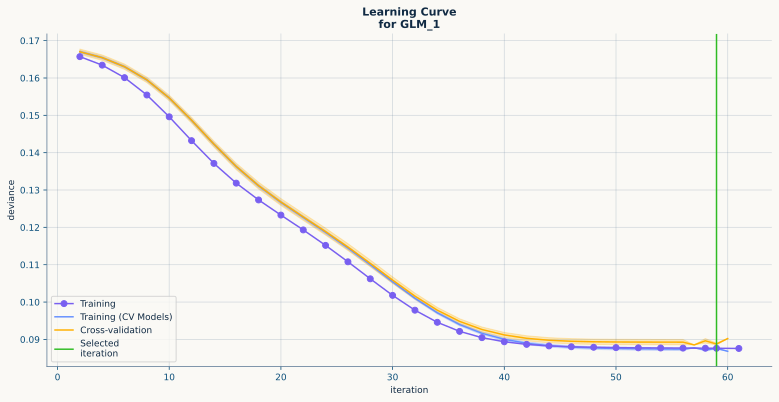

# Variable Importance

> The variable importance plot shows the relative importance of the most important variables in the model.

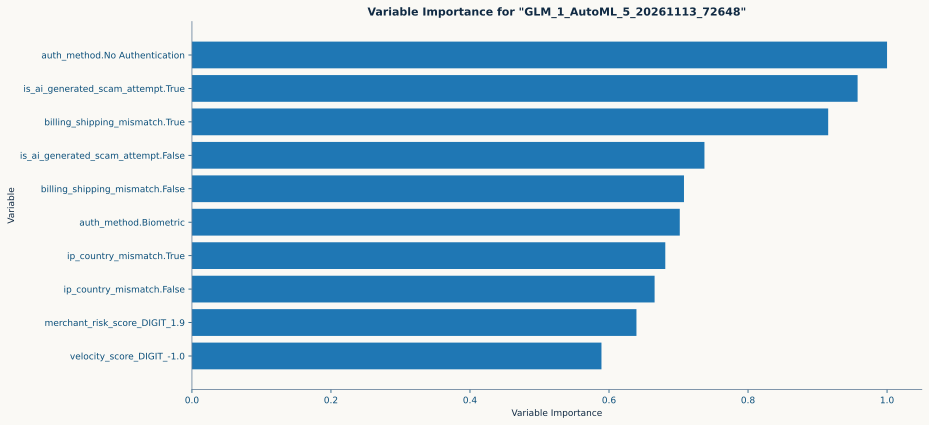

# Variable Importance Heatmap

> Variable importance heatmap shows variable importance across multiple models. Some models in H2O return variable importance for one-hot (binary indicator) encoded versions of categorical columns (e.g. Deep Learning, XGBoost). In order for the variable importance of categorical columns to be compared across all model types we compute a summarization of the the variable importance across all one-hot encoded features and return a single variable importance for the original categorical feature. By default, the models and variables are ordered by their similarity.

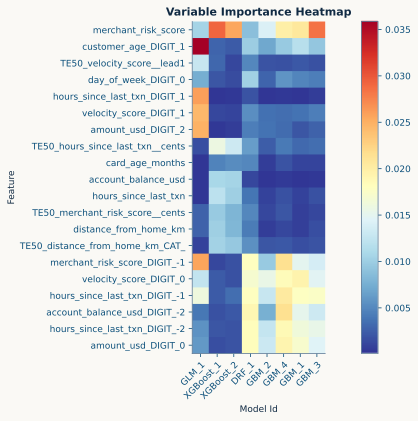

# Model Correlation

> This plot shows the correlation between the predictions of the models. For classification, frequency of identical predictions is used. By default, models are ordered by their similarity (as computed by hierarchical clustering). Interpretable models, such as GAM, GLM, and RuleFit are highlighted using red colored text.

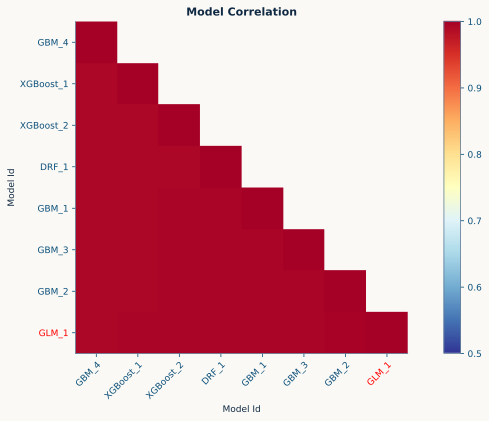

# Leaderboard

> Leaderboard shows models with their metrics. When provided with H2OAutoML object, the leaderboard shows 5-fold cross-validated metrics by default (depending on the H2OAutoML settings), otherwise it shows metrics computed on the frame. At most 20 models are shown by default.

model_id,auc,logloss,aucpr,mean_per_class_error,rmse,mse,training_time_ms,predict_time_per_row_ms,algo
GLM_1_AutoML_5_20261113_72648,0.943748,0.0459979,0.508023,0.255221,0.105061,0.0110378,203837,0.002515,GLM
GBM_2_AutoML_5_20261113_72648,0.939645,0.0495575,0.446944,0.266498,0.10922,0.0119291,165991,0.016842,GBM
GBM_3_AutoML_5_20261113_72648,0.937786,0.0500801,0.452966,0.291285,0.10935,0.0119573,160617,0.014716,GBM
GBM_1_AutoML_5_20261113_72648,0.931995,0.0506218,0.449545,0.291923,0.108933,0.0118663,222474,0.016375,GBM
GBM_4_AutoML_5_20261113_72648,0.931814,0.0537516,0.403947,0.293538,0.11304,0.0127781,141259,0.012135,GBM
XGBoost_2_AutoML_5_20261113_72648,0.928677,0.0514877,0.44063,0.278268,0.109644,0.0120217,511968,0.004994,XGBoost
XGBoost_1_AutoML_5_20261113_72648,0.924912,0.0530611,0.426751,0.299398,0.110467,0.012203,688887,0.008213,XGBoost
DRF_1_AutoML_5_20261113_72648,0.916678,0.0534275,0.426261,0.295255,0.11059,0.0122301,177534,0.018195,DRF


# Confusion Matrix

> Confusion matrix shows a predicted class vs an actual class.

## GLM_1_AutoML_5_20261113_72648

,0,1,Error,Rate
0,136570.0,1084.0,0.0079,(1084.0/137654.0)
1,1175.0,1163.0,0.5026,(1175.0/2338.0)
Total,137745.0,2247.0,0.0161,(2259.0/139992.0)


# Learning Curve Plot

> Learning curve plot shows the loss function/metric dependent on number of iterations or trees for tree-based algorithms. This plot can be useful for determining whether the model overfits.

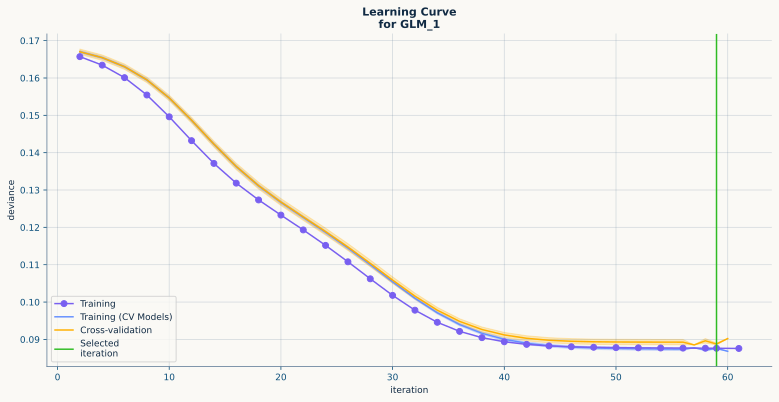

# Variable Importance

> The variable importance plot shows the relative importance of the most important variables in the model.

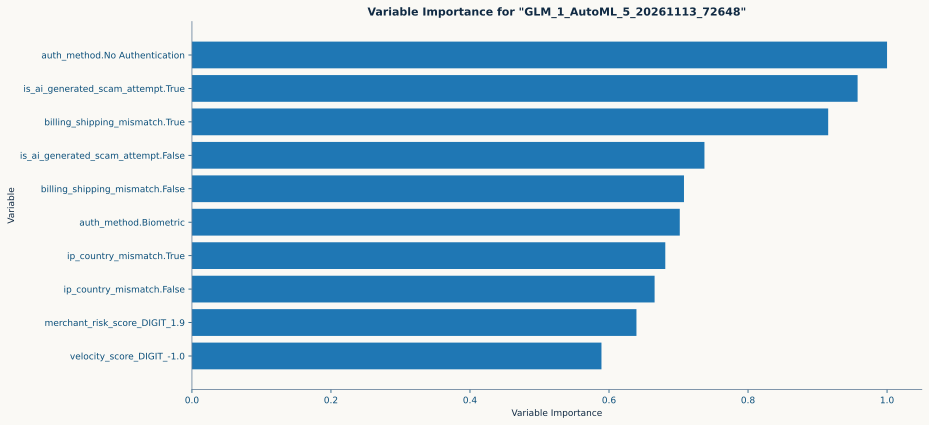

# Variable Importance Heatmap

> Variable importance heatmap shows variable importance across multiple models. Some models in H2O return variable importance for one-hot (binary indicator) encoded versions of categorical columns (e.g. Deep Learning, XGBoost). In order for the variable importance of categorical columns to be compared across all model types we compute a summarization of the the variable importance across all one-hot encoded features and return a single variable importance for the original categorical feature. By default, the models and variables are ordered by their similarity.

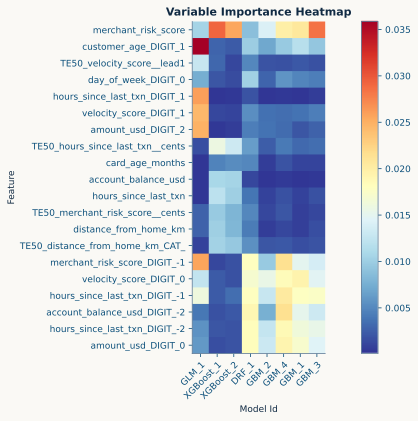

# Model Correlation

> This plot shows the correlation between the predictions of the models. For classification, frequency of identical predictions is used. By default, models are ordered by their similarity (as computed by hierarchical clustering). Interpretable models, such as GAM, GLM, and RuleFit are highlighted using red colored text.

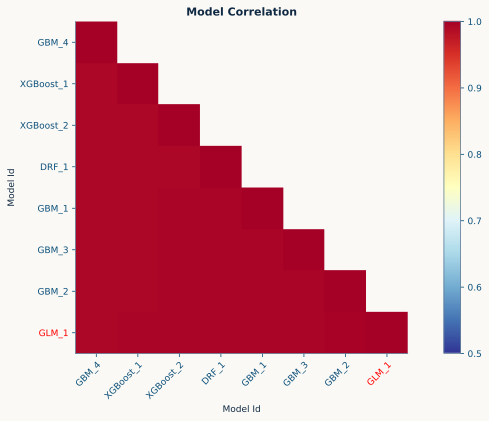

In [33]:
h2o.explain(
    get_model['model'], get_model['val_data'],
    exclude_explanations=[
        "pdp",
        "shap_summary", # Issues with shap display
    ],
    top_n_features=3,
    figsize=(13, 6),
)

In [34]:
h2o.cluster().shutdown()

In [35]:
# !rm -r /kaggle/working/ 